# 01 — Exploratory Data Analysis: Instacart 2017

**Goal:** understand purchase behaviour before modelling replenishment and recommendations.

Inputs: `data/processed/orders_clean.parquet`, `order_products_clean.parquet` (from `src.data.preprocess`).
Figures are saved to `reports/figures/`.

> Each section ends with a **Takeaway** cell. Fill these in in your own words; they feed directly into the Milestone 2 write-up and the viva.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED_DIR, FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)

con = duckdb.connect()
P = lambda n: (PROCESSED_DIR / f"{n}.parquet").as_posix()
con.execute(f"CREATE VIEW orders AS SELECT * FROM '{P('orders_clean')}'")
con.execute(f"CREATE VIEW op AS SELECT * FROM '{P('order_products_clean')}'")
con.execute(f"CREATE VIEW products AS SELECT * FROM '{P('products')}'")
con.execute(f"CREATE VIEW departments AS SELECT * FROM '{P('departments')}'")
con.execute(f"CREATE VIEW aisles AS SELECT * FROM '{P('aisles')}'")
q = lambda sql: con.execute(sql).df()

def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150)
    plt.show()

## 1. Dataset overview

In [2]:
q('''
SELECT
  (SELECT COUNT(DISTINCT user_id)    FROM orders) AS users,
  (SELECT COUNT(*)                   FROM orders) AS orders,
  (SELECT COUNT(*)                   FROM op)     AS order_items,
  (SELECT COUNT(DISTINCT product_id) FROM op)     AS products_purchased,
  (SELECT COUNT(*) FROM products)                 AS products_catalogue,
  (SELECT AVG(reordered)             FROM op)     AS overall_reorder_rate
''')

,users,orders,order_items,products_purchased,products_catalogue,overall_reorder_rate
0,206209,3346083,33819106,49685,49688,0.590062


In [3]:
q('SELECT split, COUNT(DISTINCT order_id) AS orders, COUNT(*) AS items FROM op GROUP BY split ORDER BY split')

,split,orders,items
0,history,2933665,29524435
1,test,206209,2165417
2,val,206209,2129254


**Takeaway:** _…_

## 2. Orders per user
How much history do we have per user? Short histories mean a cold-start risk.

count    206209.000000
mean         16.226658
std          16.662238
min           3.000000
25%           6.000000
50%          10.000000
75%          20.000000
max         100.000000
Name: n_orders, dtype: float64

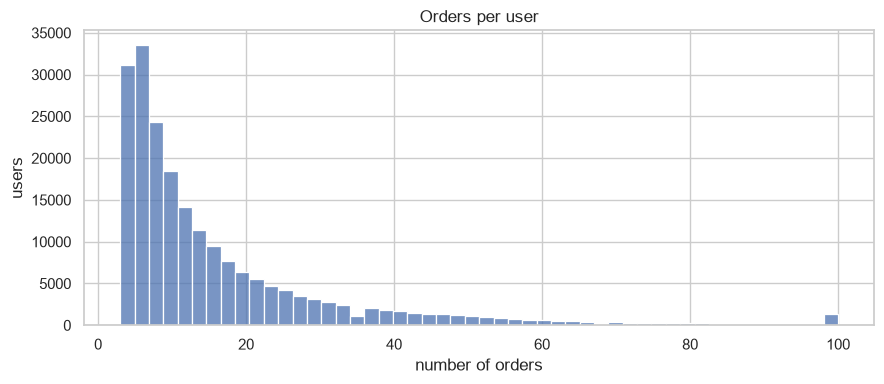

In [4]:
opu = q('SELECT user_id, COUNT(*) AS n_orders FROM orders GROUP BY user_id')
display(opu['n_orders'].describe())
sns.histplot(opu['n_orders'], bins=50)
plt.title('Orders per user'); plt.xlabel('number of orders'); plt.ylabel('users')
save('01_orders_per_user')

### Takeaway

**Observation:** The distribution is heavily right-skewed. Most users have only **4–10 orders** (peak ≈ 5–6), and the count falls off quickly after that. The spike at **100** is an artefact: Instacart capped histories at 100 orders. The minimum is 3 because Kaggle "test" users lost their unlabelled final order.

**Implications:**

- **Cold start:** many users have short histories, so per-item interval features will be noisy. User- and product-level features and a popularity fallback are needed.
- **Evaluation:** report results separately for short-history (≤ 5 orders) and long-history users.
- **Heavy users:** the users capped at 100 orders could dominate training, so consider capping the history window or weighting by user.

## 3. Days between orders
Note the spike at 30: values are capped, so 30 means "30 or more days".

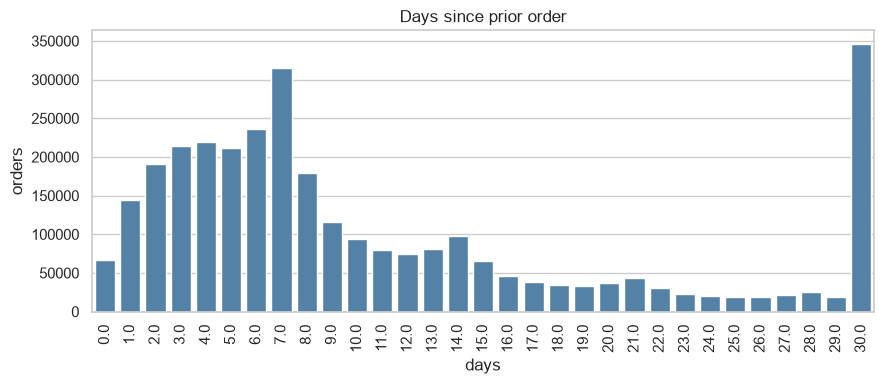

Share capped at 30: 0.11


In [5]:
d = q('SELECT days_since_prior_order AS d, COUNT(*) AS n FROM orders WHERE order_number > 1 GROUP BY d ORDER BY d')
sns.barplot(data=d, x='d', y='n', color='steelblue')
plt.title('Days since prior order'); plt.xlabel('days'); plt.ylabel('orders')
plt.xticks(rotation=90)
save('02_days_since_prior')
print('Share capped at 30:', round(d.loc[d.d == 30, 'n'].sum() / d.n.sum(), 3))

### Takeaway

**Observation:** Most repeat orders come within **1–8 days**. The highest bar is at **7 days**, with smaller bumps at **14, 21 and 28**, showing a clear **weekly shopping rhythm**. The spike at **30** is an artefact of the cap: about **11%** of gaps are really "30 or more days". Some orders come **0 days** after the previous one (same-day top-ups).

**Implications:**

- **Features:** weekly multiples are a strong timing signal. Use days since the last purchase relative to the user's usual gap.
- **30-day cap:** flag capped gaps (`days_capped`). Timelines after a capped gap are approximate, and timing MAE/RMSE will understate error for infrequent shoppers. Note this as a limitation.
- **Same-day orders:** consider merging them when computing item repurchase gaps, to avoid inflating purchase frequency.

## 4. When do people shop?

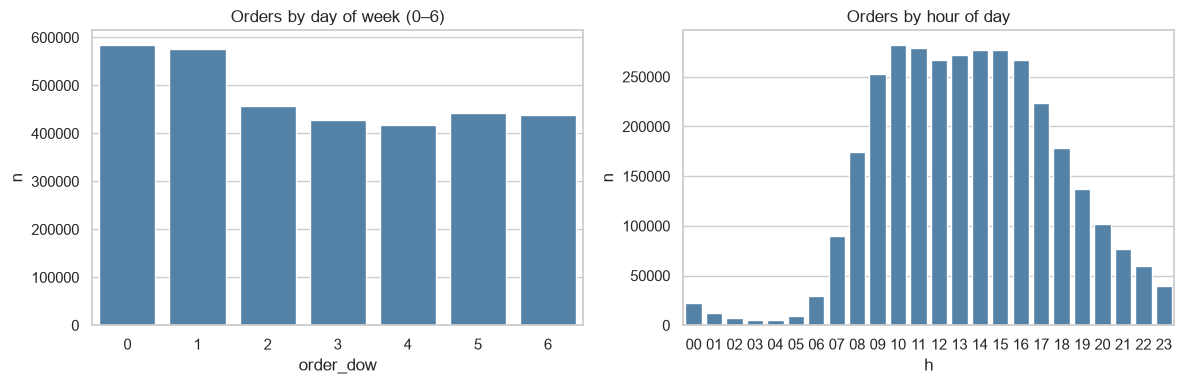

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dow = q('SELECT order_dow, COUNT(*) n FROM orders GROUP BY 1 ORDER BY 1')
hr = q('SELECT order_hour_of_day h, COUNT(*) n FROM orders GROUP BY 1 ORDER BY 1')
sns.barplot(data=dow, x='order_dow', y='n', ax=ax[0], color='steelblue'); ax[0].set_title('Orders by day of week (0–6)')
sns.barplot(data=hr, x='h', y='n', ax=ax[1], color='steelblue'); ax[1].set_title('Orders by hour of day')
save('03_dow_hour')

### Takeaway

**Observation:** Days **0 and 1** are the busiest (≈ 580K vs 415–455K on other days, about 30% more), commonly read as **Sunday and Monday**, which suggests a weekend / start-of-week restock. Within the day, ordering rises sharply from **7 AM**, stays high from **9 AM to 4 PM** (peak ≈ 10 AM), then declines through the evening. There's very little activity between midnight and 6 AM.

**Implications:**

- **Features:** each user's usual shopping day and hour, plus the next order's day and hour, as context features.
- **System design:** peak hours define the API load to plan for (RQ5). Shopping lists could be generated in an overnight batch during the quiet hours.
- **Limitation:** the mapping of day 0 to Sunday is assumed, not documented by Instacart.

## 5. Basket size

count    3.346083e+06
mean     1.010707e+01
std      7.542326e+00
min      1.000000e+00
25%      5.000000e+00
50%      8.000000e+00
75%      1.400000e+01
max      1.450000e+02
Name: basket_size, dtype: float64

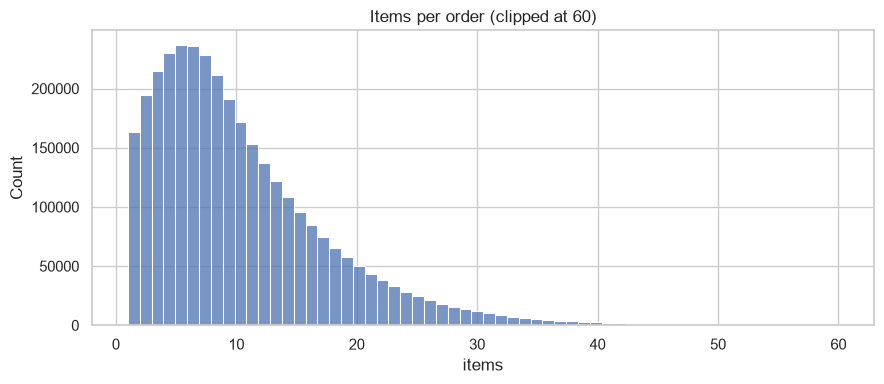

In [7]:
bs = q('SELECT order_id, COUNT(*) AS basket_size FROM op GROUP BY order_id')
display(bs['basket_size'].describe())
sns.histplot(bs['basket_size'].clip(upper=60), bins=60)
plt.title('Items per order (clipped at 60)'); plt.xlabel('items')
save('04_basket_size')

### Takeaway

**Observation:** Basket sizes are right-skewed. Across **3.35M orders**, the **median is 8 items** and the **mean 10.1** (std 7.5). Half of orders have **5–14 items**, the most common size is ≈ 5–7, and very few exceed 40 (max 145).

**Implications:**

- **Choice of K:** K = 5, 10, 20 are well matched. 5 is below the median, 10 is close to the mean, and 20 covers most baskets (above the 75th percentile of 14).
- **Fairer metrics:** baskets vary from 1 to 145 items, so also report F1 with a per-user threshold, or set K to the user's average basket size.
- **Feature:** each user's average basket size indicates how long their predicted list should be.
- **Association rules:** small baskets mean low support for item pairs, so FP-Growth needs a low minimum support or aisle/department-level rules.

## 6. Top products and departments

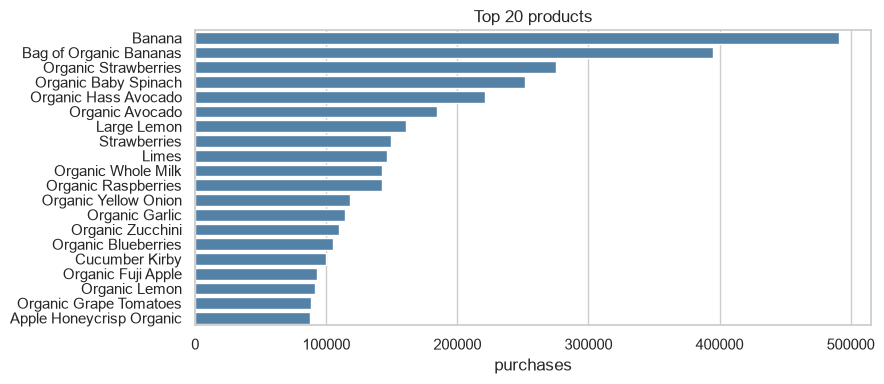

,product_name,purchases,reorder_rate
0,Banana,491291,0.845051
1,Bag of Organic Bananas,394930,0.833755
2,Organic Strawberries,275577,0.778178
3,Organic Baby Spinach,251705,0.774474
4,Organic Hass Avocado,220877,0.797607
5,Organic Avocado,184224,0.761410
6,Large Lemon,160792,0.697659
7,Strawberries,149445,0.699843
8,Limes,146660,0.681863
9,Organic Whole Milk,142813,0.831045


In [8]:
top = q('''
SELECT p.product_name, COUNT(*) AS purchases, AVG(op.reordered) AS reorder_rate
FROM op JOIN products p USING (product_id)
GROUP BY 1 ORDER BY purchases DESC LIMIT 20''')
sns.barplot(data=top, y='product_name', x='purchases', color='steelblue')
plt.title('Top 20 products'); plt.ylabel('')
save('05_top_products')
top

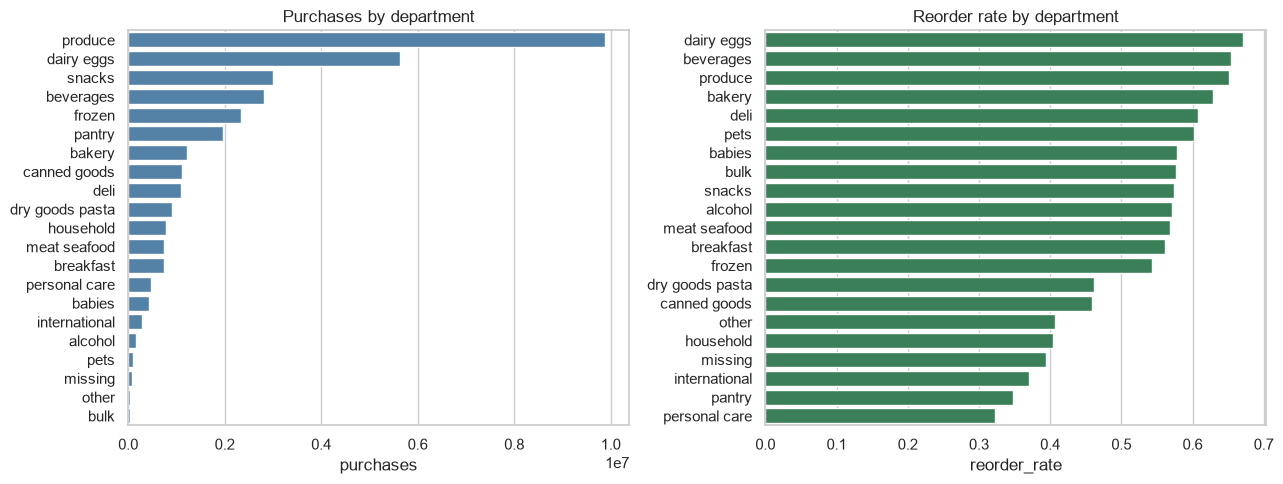

In [9]:
dep = q('''
SELECT d.department, COUNT(*) AS purchases, AVG(op.reordered) AS reorder_rate
FROM op JOIN departments d USING (department_id)
GROUP BY 1 ORDER BY purchases DESC''')
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=dep, y='department', x='purchases', ax=ax[0], color='steelblue'); ax[0].set_title('Purchases by department')
sns.barplot(data=dep.sort_values('reorder_rate', ascending=False), y='department', x='reorder_rate', ax=ax[1], color='seagreen')
ax[1].set_title('Reorder rate by department')
for a in ax: a.set_ylabel('')
save('06_departments')

### Takeaway

**Observation:** Purchases are concentrated: **produce** (≈ 9.9M) and **dairy & eggs** (≈ 5.6M) make up nearly half of all items. Reorder rates split departments into two groups:

- **Repetitive / habitual (reorder rate above ≈ 0.6):** dairy & eggs (≈ 0.67), beverages, produce, bakery, deli, pets.
- **Exploratory / occasional (below ≈ 0.45):** personal care (≈ 0.32, the lowest), pantry, international, household, canned goods.
- **Small but loyal:** pets, babies and bulk have low volume but high reorder rates (brand loyalty).

**Implications:**

- **Two-part design:** replenishment suits habitual departments; recommendations and association rules add the most value in exploratory ones.
- **Features:** department/aisle and product reorder rates help with cold start.
- **Explainability:** the department can drive the reason shown for each item (e.g. *"You restock dairy every ~7 days"*).
- **Data quality:** the **"missing"** and **"other"** departments are products with no category. Keep them as their own category rather than dropping them.

## 7. Reorders and cart position
Are items added to the cart first more likely to be reorders (habitual items)?

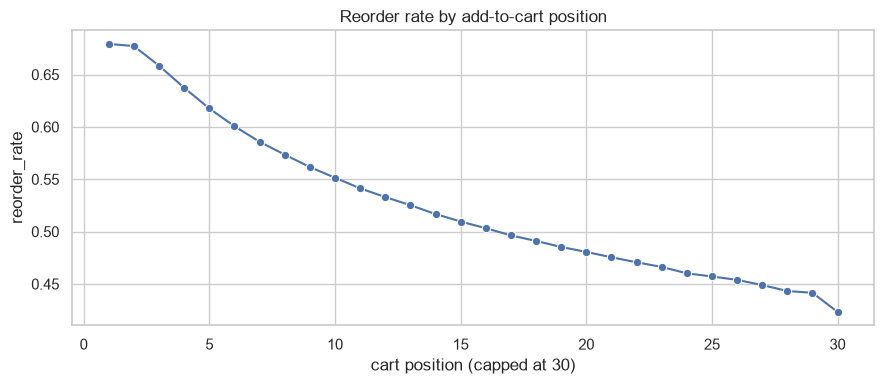

In [10]:
cart = q('SELECT LEAST(add_to_cart_order, 30) AS pos, AVG(reordered) AS reorder_rate FROM op GROUP BY 1 ORDER BY 1')
sns.lineplot(data=cart, x='pos', y='reorder_rate', marker='o')
plt.title('Reorder rate by add-to-cart position'); plt.xlabel('cart position (capped at 30)')
save('07_cart_position')

### Takeaway

**Observation:** The reorder rate falls steadily with cart position. Items added **1st or 2nd** are reorders **≈ 68%** of the time, dropping to ≈ 55% by position 10 and ≈ 45% by 25–30. The last point (30) groups every position from 30 onwards. People add **habitual staples first**, then browse for new items.

**Implications:**

- **Feature, avoiding leakage:** the cart position in the order being predicted isn't known in advance, so it can't be used. Use **historical** averages instead: the user's mean cart position for the item, and the product's mean cart position across all users.
- **Ranking:** put habitual items at the top of the predicted list, matching how people shop.
- **Two-stage behaviour:** the early cart is habitual (replenishment) and the later cart is exploratory (recommendations and association rules).

## 8. Repurchase intervals per user–item (core to replenishment)
For each user–product bought at least twice in history: the gap in days between consecutive purchases.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

count    1.180702e+06
mean     2.829840e+01
std      3.578162e+01
min      0.000000e+00
25%      7.000000e+00
50%      1.500000e+01
75%      3.200000e+01
max      3.590000e+02
Name: gap, dtype: float64

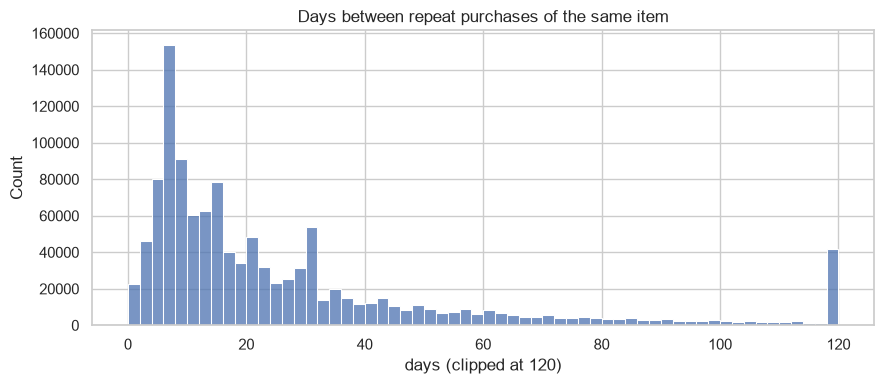

In [11]:
con.execute('''
CREATE OR REPLACE TABLE gaps AS
SELECT user_id, product_id, aisle_id,
       day_index - LAG(day_index) OVER (PARTITION BY user_id, product_id ORDER BY order_number) AS gap
FROM op WHERE split = 'history'
''')
g = q('SELECT gap FROM gaps WHERE gap IS NOT NULL USING SAMPLE 2000000 ROWS')
display(g['gap'].describe())
sns.histplot(g['gap'].clip(upper=120), bins=60)
plt.title('Days between repeat purchases of the same item'); plt.xlabel('days (clipped at 120)')
save('08_repurchase_gap')

383,336 user–item pairs with at least 3 repeat purchases (20% user sample)


,mean_gap,cv,n
count,383336.000000,383329.000000,383336.000000
mean,28.801005,0.752644,7.164764
std,18.621198,0.347879,6.352408
min,0.000000,0.000000,3.000000
25%,15.235294,0.514043,3.000000
50%,24.000000,0.706428,5.000000
75%,37.333333,0.943499,8.000000
max,120.666667,3.790301,94.000000


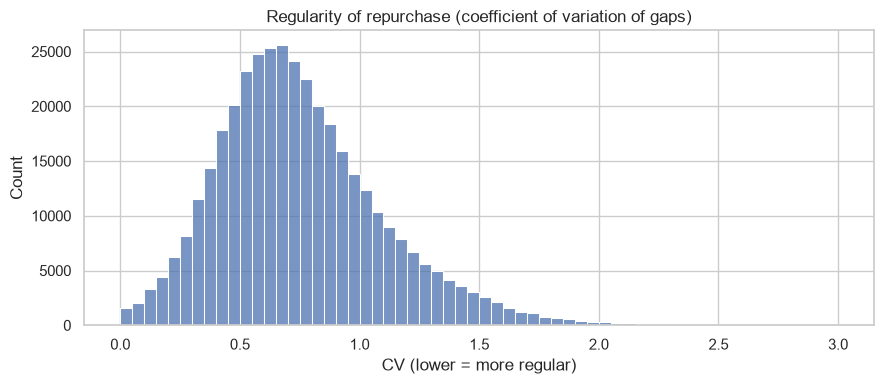

In [3]:
# Regularity of repurchase, on a 20% user sample to limit memory and time
con.execute("SET memory_limit='4GB'")
con.execute(f"SET temp_directory='{(PROCESSED_DIR / 'duckdb_tmp').as_posix()}'")

con.execute('''
CREATE OR REPLACE TABLE item_regularity AS
WITH g AS (
  SELECT user_id, product_id,
         day_index - LAG(day_index) OVER (PARTITION BY user_id, product_id ORDER BY order_number) AS gap
  FROM op
  WHERE split = 'history' AND user_id % 5 = 0
)
SELECT user_id, product_id,
       AVG(gap) AS mean_gap, STDDEV_SAMP(gap) AS sd_gap, COUNT(*) AS n
FROM g WHERE gap IS NOT NULL
GROUP BY 1, 2 HAVING COUNT(*) >= 3
''')

reg = q("SELECT mean_gap, sd_gap / NULLIF(mean_gap, 0) AS cv, n FROM item_regularity")
print(f"{len(reg):,} user–item pairs with at least 3 repeat purchases (20% user sample)")
display(reg.describe())

sns.histplot(reg['cv'].dropna().clip(upper=3), bins=60)
plt.title('Regularity of repurchase (coefficient of variation of gaps)')
plt.xlabel('CV (lower = more regular)')
save('09_repurchase_regularity')

### Takeaway: Regularity of repurchase

**Observation:** For user–item pairs with at least 3 repeat purchases (20% user sample), the coefficient of variation (CV) of gaps peaks at **≈ 0.6–0.7**, with a median of **[median cv from describe]**. Very few pairs are perfectly regular (CV near 0), and almost none go above 2. In practice, a habit of "milk every ~7 days" usually varies by about ±4–5 days rather than being exact.

- **Fairly regular (CV < 0.5):** a sizeable group of items restocked on a consistent cycle. These are the most predictable replenishment candidates.
- **Moderately regular (CV ≈ 0.5–1.0):** the majority. There is a clear habit, but the exact timing shifts.
- **Irregular (CV > 1):** occasional or impulse repeats where timing is a weak signal.

**Implications:**

- **Justifies interval/recency features:** most habits are regular enough that *days since last purchase ÷ mean gap* is informative, but noisy enough that a fixed rule ("buy every N days") will often be wrong. This motivates an ML model over the fixed-interval baseline (RQ2, RQ4).
- **CV as a feature:** include each user–item pair's gap CV, so the model learns how much to trust the timing signal for each item.
- **Explainability:** show timing reasons only for regular items (low CV), e.g. *"You buy this about every 7 days, and it's been 8."*
- **Sample note:** computed on 20% of users (`user_id % 5 = 0`) to limit memory use; the shape of the distribution is representative.

## 9. How predictable is the next order?
For each user's **test** order: what share of its items had already been bought in history + val?
This is the upper bound on what replenishment alone can recover; the rest needs recommendation.

count    206209.000000
mean          0.598701
std           0.308092
min           0.000000
25%           0.363636
50%           0.625000
75%           0.863636
max           1.000000
Name: share_seen, dtype: float64

Overall share of test items previously bought: 0.594


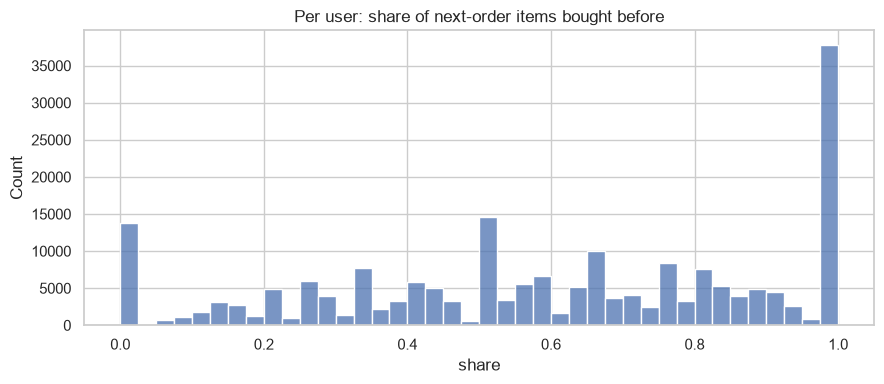

In [4]:
cov = q('''
WITH past AS (SELECT DISTINCT user_id, product_id FROM op WHERE split IN ('history','val')),
t AS (SELECT o.user_id, o.product_id, p.product_id IS NOT NULL AS seen
      FROM op o LEFT JOIN past p USING (user_id, product_id) WHERE o.split = 'test')
SELECT user_id, AVG(seen::INT) AS share_seen, COUNT(*) AS basket FROM t GROUP BY user_id''')
display(cov['share_seen'].describe())
print('Overall share of test items previously bought:', round(q("""
WITH past AS (SELECT DISTINCT user_id, product_id FROM op WHERE split IN ('history','val'))
SELECT AVG((p.product_id IS NOT NULL)::INT) FROM op o LEFT JOIN past p USING (user_id, product_id) WHERE o.split='test'""").iat[0,0], 3))
sns.histplot(cov['share_seen'], bins=40)
plt.title('Per user: share of next-order items bought before'); plt.xlabel('share')
save('10_next_order_coverage')

In [5]:
cand = q('''
WITH past AS (SELECT DISTINCT user_id, product_id FROM op WHERE split IN ('history','val')),
t AS (SELECT DISTINCT user_id, product_id FROM op WHERE split = 'test')
SELECT COUNT(*) AS candidates, SUM((t.product_id IS NOT NULL)::INT) AS positives
FROM past LEFT JOIN t USING (user_id, product_id)''')
cand['positive_rate'] = cand.positives / cand.candidates
cand

,candidates,positives,positive_rate
0,12984631,1286302.0,0.099063


### Takeaway: How predictable is the next order?

**Observation:**

- **59.4%** of items in users' next (test) order had **already been bought** in their history, so most grocery shopping is repeat buying.
- Per user, the median share is **62.5%** (IQR 36–86%). About **38K users (≈ 18%)** bought *only* previously purchased items, while about **14K (≈ 7%)** bought *only* new items.
- Replenishment candidates (every item each user has bought before): **12.98M** user–item pairs, of which **1.29M (9.9%)** appear in the next order. That's about **63 candidates per user** against a typical basket of about 10 items.

**Implications:**

- **Justifies replenishment as core capability 1:** predicting repeats can cover up to about 59% of the next order. This is also the **upper bound on recall** for any replenishment-only approach.
- **Justifies recommendation as core capability 2:** the remaining **≈ 41% are new items** that replenishment can never predict. Collaborative filtering and association rules are needed to cover them.
- **Class imbalance (≈ 1 : 9):** accuracy would be misleading (predicting "no" for everything gives 90%). Use **PR-AUC, F1 and threshold tuning**, and consider class weighting.
- **User heterogeneity:** the spread from 0 to 1 means some users are highly habitual and others exploratory. A user-level **"habit ratio"** (share of reorders in past orders) is a valuable feature, and it can decide how much of each user's list should be replenishment versus recommendation.

## 10. Summary for Milestone 2

**Data quality notes:**

- No calendar dates: timelines are rebuilt from `days_since_prior_order`, which is **capped at 30** (≈ 11% of gaps), so long gaps are underestimated.
- No quantity field: demand is modelled as *whether and when*, not *how much*.
- Short histories: most users have 4–10 orders (cold-start risk). Histories are capped at 100 orders.
- A small share of products fall in the "missing" and "other" departments; they're kept as their own category.
- Same-day (0-day) repeat orders exist and may inflate purchase frequency.

**Key behavioural patterns:**

- Strong **weekly rhythm**: peaks at 7, 14, 21 and 28 days, both between orders and between repeat purchases of the same item.
- Shopping concentrates on **days 0–1** and between **9 AM and 4 PM**.
- Typical basket: **median 8, mean 10 items**.
- **Habitual departments** (dairy, beverages, produce, bakery: reorder rate ≈ 0.6–0.67) versus **exploratory** ones (personal care, pantry, household: ≈ 0.32–0.45).
- Habitual items are **added to the cart first** (≈ 68% reorders at position 1 vs ≈ 45% by position 25).
- Repurchase is **moderately regular** (gap CV peaks at ≈ 0.6–0.7).
- **59.4%** of next-order items are repeats; **41%** are new.

**Implications for features and models:**

- User–item features: purchase count, recency (orders and days), mean gap, gap CV, **days since last purchase ÷ mean gap**, mean historical cart position.
- User features: number of orders, mean basket size, habit ratio, usual day and hour.
- Product, aisle and department features: popularity, reorder rate, mean cart position.
- Candidate set: all previously bought items (≈ 63 per user); a binary classifier (Logistic Regression as baseline, LightGBM as the improved model).
- Collaborative filtering and association rules are needed for the ≈ 41% of new items.

**Implications for evaluation:**

- Imbalanced target (9.9% positive): use **PR-AUC, F1 and threshold tuning**, not accuracy.
- Ranking: **Precision@K, Recall@K and Hit Rate@K at K = 5, 10, 20**, matched to basket sizes.
- Report results separately for **short- and long-history users**.
- Replenishment recall is bounded at **≈ 59%**, and results should be read against that ceiling.
- Baselines: user's most frequent items, repeat of last order, fixed-interval rule, global popularity.